# 🫀 트랜스포머(Transformer)를 활용한 심전도(ECG) 이상 탐지 (분류)

본 실습 노트북은 공개 의료 시계열 데이터셋인 **ECG5000 (PhysioNet BIDMC 울혈성 심부전 환자 심박 데이터, OpenML ID: 44793)**을 활용하여, **Transformer Encoder** 아키텍처로 정상 심박(Normal)과 이상 심박(부정맥 등 Anomaly)을 분류(Classification)하는 강좌용 예제입니다.

### 📋 실습 목차
1. **환경 설정 및 라이브러리 임포트**
2. **공개 심전도(ECG5000) 데이터셋 로드 및 분할 (Train / Validation / Test)**
3. **PyTorch Dataset 및 DataLoader 구성**
4. **Positional Encoding 및 시계열 Transformer 모델 정의**
5. **모델 학습 (Train) 및 검증 (Validation)**
6. **테스트 평가 (Test) 및 종합 결과 시각화**

## 1. 환경 설정 및 라이브러리 임포트
실습에 필요한 PyTorch, NumPy, Matplotlib, Scikit-learn 라이브러리를 불러오고 시드를 고정합니다.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_curve, auc
)

# 재현성을 위한 시드 고정
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'사용 중인 디바이스: {device}')

사용 중인 디바이스: cpu


## 2. 공개 심전도(ECG5000) 데이터 로드 및 분할 (Train / Validation / Test)

- **데이터셋 설명**: PhysioNet의 BIDMC Congestive Heart Failure Database에서 추출되어 공개된 **ECG5000** 데이터셋을 `scikit-learn`의 `fetch_openml`을 통해 직접 다운로드합니다.
- **데이터 구조**: 총 5,000개의 심박(Heartbeat) 샘플로 구성되어 있으며, 각 샘플은 **140개의 타임스텝(Time Step)**을 가진 시계열 파형과 클래스 라벨(`1`: 정상 심박, `2~5`: 조기심실수축 등 이상 심박)로 이루어져 있습니다.
- **라벨 변환**: 이상 탐지(이진 분류) 기준에 맞추어 **정상 심박(Class 1)을 `0`**, **이상 심박(Class 2~5)을 `1`**로 변환합니다.

ECG5000 데이터셋 다운로드 중...
전체 ECG 데이터 형태: (4998, 140) (샘플 수: 4998, 시계열 길이: 140)
Train 데이터 형태: (3498, 140, 1) | 이상 심박 비율: 41.60%
Validation 데이터 형태: (750, 140, 1) | 이상 심박 비율: 41.60%
Test 데이터 형태: (750, 140, 1) | 이상 심박 비율: 41.60%


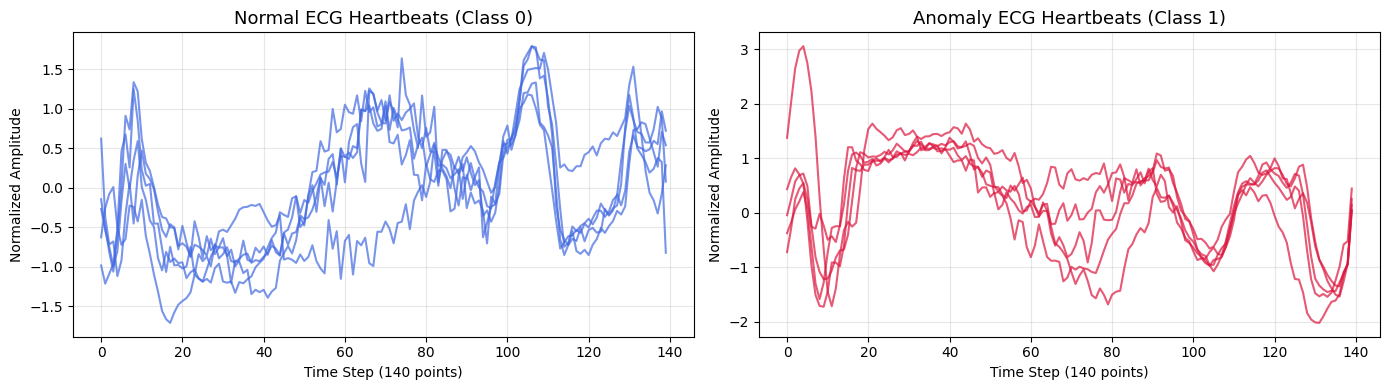

In [2]:
# Scikit-learn 내장 OpenML 로더를 통해 공개 의료 데이터셋 ECG5000 다운로드
print('ECG5000 데이터셋 다운로드 중...')
ecg = fetch_openml(name='ECG5000', version=1, as_frame=False, parser='auto')

raw_data = ecg.data.astype(np.float32)  # Shape: (5000, 140)
raw_target = ecg.target.astype(int)     # 1: Normal, 2~5: Anomaly (Arrhythmia 등)

# Normal(1) -> 0, Anomaly(2,3,4,5) -> 1 로 이진 라벨 매핑
y = np.where(raw_target == 1, 0, 1).astype(np.int64)

print(f'전체 ECG 데이터 형태: {raw_data.shape} (샘플 수: {raw_data.shape[0]}, 시계열 길이: {raw_data.shape[1]})')

# Train (70%), Validation (15%), Test (15%) 계층적 분할 (Stratified Split)
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    raw_data, y, test_size=0.3, stratify=y, random_state=SEED
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED
)

# 데이터 정규화 (Train 데이터 기준으로 StandardScaler 피팅 후 변환)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

# Transformer 입력 형태인 (Batch, Seq_Len=140, Feature_Dim=1)로 차원 확장
X_train = X_train_scaled[..., np.newaxis]
X_val = X_val_scaled[..., np.newaxis]
X_test = X_test_scaled[..., np.newaxis]

print(f'Train 데이터 형태: {X_train.shape} | 이상 심박 비율: {y_train.mean():.2%}')
print(f'Validation 데이터 형태: {X_val.shape} | 이상 심박 비율: {y_val.mean():.2%}')
print(f'Test 데이터 형태: {X_test.shape} | 이상 심박 비율: {y_test.mean():.2%}')

# 정상 심박 vs 이상 심박 파형 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
normal_indices = np.where(y_train == 0)[0][:5]
anomaly_indices = np.where(y_train == 1)[0][:5]

for idx in normal_indices:
    axes[0].plot(X_train[idx].squeeze(), color='royalblue', alpha=0.7, lw=1.5)
axes[0].set_title('Normal ECG Heartbeats (Class 0)', fontsize=13)
axes[0].set_xlabel('Time Step (140 points)')
axes[0].set_ylabel('Normalized Amplitude')
axes[0].grid(True, alpha=0.3)

for idx in anomaly_indices:
    axes[1].plot(X_train[idx].squeeze(), color='crimson', alpha=0.7, lw=1.5)
axes[1].set_title('Anomaly ECG Heartbeats (Class 1)', fontsize=13)
axes[1].set_xlabel('Time Step (140 points)')
axes[1].set_ylabel('Normalized Amplitude')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. PyTorch Dataset 및 DataLoader 구성

In [3]:
class ECGDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 64
train_loader = DataLoader(ECGDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(ECGDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(ECGDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

## 4. Positional Encoding 및 시계열 Transformer 모델 정의
- **Input Projection**: 각 시점의 1차원 ECG 진폭(Amplitude)을 `d_model` 차원의 벡터로 투영합니다.
- **Positional Encoding**: 심박 파형(P파, QRS 복합파, T파)의 시간적 순서 정보를 모델에 주입합니다.
- **Transformer Encoder**: Multi-Head Self-Attention을 통해 심박 주기 내 시점 간의 상관관계와 비정상 파형 징후를 포착합니다.
- **Global Average Pooling & Classifier**: 140개 시점의 표현을 요약하여 정상(0) / 이상(1) 심박을 분류합니다.

In [4]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)  # Shape: (1, max_len, d_model)
        self.register_buffer('pe', pe)

    def forward(self, x):
        # x: (batch_size, seq_len, d_model)
        return x + self.pe[:, :x.size(1), :]

class ECGTransformerClassifier(nn.Module):
    def __init__(self, input_dim=1, d_model=64, nhead=4, num_layers=2, dim_feedforward=128, dropout=0.1, num_classes=2):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        self.classifier = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        # 1. 입력 차원 확장: (B, 140, 1) -> (B, 140, d_model)
        x = self.input_proj(x)
        # 2. 위치 인코딩 추가
        x = self.pos_encoder(x)
        # 3. 트랜스포머 인코더 통과
        x = self.transformer_encoder(x)
        # 4. Global Average Pooling: (B, 140, d_model) -> (B, d_model)
        x = x.mean(dim=1)
        # 5. 분류기 통과
        logits = self.classifier(x)
        return logits

model = ECGTransformerClassifier().to(device)
print(model)

ECGTransformerClassifier(
  (input_proj): Linear(in_features=1, out_features=64, bias=True)
  (pos_encoder): PositionalEncoding()
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (classifier): Sequential(
    (0): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=64, out_features=32, bias=True)
    (2): 

## 5. 모델 학습 (Train) 및 검증 (Validation)
매 에포크마다 **Train** 손실/정확도와 **Validation** 손실/정확도를 기록하고, 검증 손실이 가장 낮은 최적의 모델 가중치를 저장합니다.

In [5]:
EPOCHS = 20
LR = 1e-3

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)

history = {
    'train_loss': [], 'val_loss': [],
    'train_acc': [], 'val_acc': []
}

best_val_loss = float('inf')
best_model_weights = None

for epoch in range(1, EPOCHS + 1):
    # --- Train ---
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * batch_x.size(0)
        preds = outputs.argmax(dim=1)
        train_correct += (preds == batch_y).sum().item()
        train_total += batch_x.size(0)

    epoch_train_loss = train_loss / train_total
    epoch_train_acc = train_correct / train_total

    # --- Validation ---
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)

            val_loss += loss.item() * batch_x.size(0)
            preds = outputs.argmax(dim=1)
            val_correct += (preds == batch_y).sum().item()
            val_total += batch_x.size(0)

    epoch_val_loss = val_loss / val_total
    epoch_val_acc = val_correct / val_total

    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_acc'].append(epoch_val_acc)

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    if epoch % 2 == 0 or epoch == 1:
        print(f'Epoch [{epoch:02d}/{EPOCHS}] | '
              f'Train Loss: {epoch_train_loss:.4f}, Acc: {epoch_train_acc:.4f} | '
              f'Val Loss: {epoch_val_loss:.4f}, Acc: {epoch_val_acc:.4f}')

# 최적의 검증 성능을 보인 가중치 복원
model.load_state_dict({k: v.to(device) for k, v in best_model_weights.items()})
print('\n✅ 학습 완료 및 최적 모델 가중치 로드 완료!')

Epoch [01/20] | Train Loss: 0.3741, Acc: 0.8508 | Val Loss: 0.1386, Acc: 0.9467
Epoch [02/20] | Train Loss: 0.0846, Acc: 0.9703 | Val Loss: 0.0626, Acc: 0.9773
Epoch [04/20] | Train Loss: 0.0604, Acc: 0.9791 | Val Loss: 0.0794, Acc: 0.9640
Epoch [06/20] | Train Loss: 0.0456, Acc: 0.9866 | Val Loss: 0.0336, Acc: 0.9893
Epoch [08/20] | Train Loss: 0.0419, Acc: 0.9889 | Val Loss: 0.0394, Acc: 0.9880
Epoch [10/20] | Train Loss: 0.0409, Acc: 0.9863 | Val Loss: 0.0650, Acc: 0.9800
Epoch [12/20] | Train Loss: 0.0341, Acc: 0.9889 | Val Loss: 0.0404, Acc: 0.9853
Epoch [14/20] | Train Loss: 0.0400, Acc: 0.9851 | Val Loss: 0.0339, Acc: 0.9893
Epoch [16/20] | Train Loss: 0.0303, Acc: 0.9900 | Val Loss: 0.0282, Acc: 0.9920
Epoch [18/20] | Train Loss: 0.0327, Acc: 0.9889 | Val Loss: 0.0406, Acc: 0.9920
Epoch [20/20] | Train Loss: 0.0258, Acc: 0.9917 | Val Loss: 0.0364, Acc: 0.9893

✅ 학습 완료 및 최적 모델 가중치 로드 완료!


## 6. 테스트 평가 (Test) 및 종합 결과 시각화
1. **학습 곡선 (Train vs Validation Loss & Accuracy)**
2. **Test 데이터 혼동 행렬 (Confusion Matrix) 및 ROC Curve**
3. **Test 샘플 ECG 파형에 대한 실제 라벨 vs 모델 예측 결과 시각화**

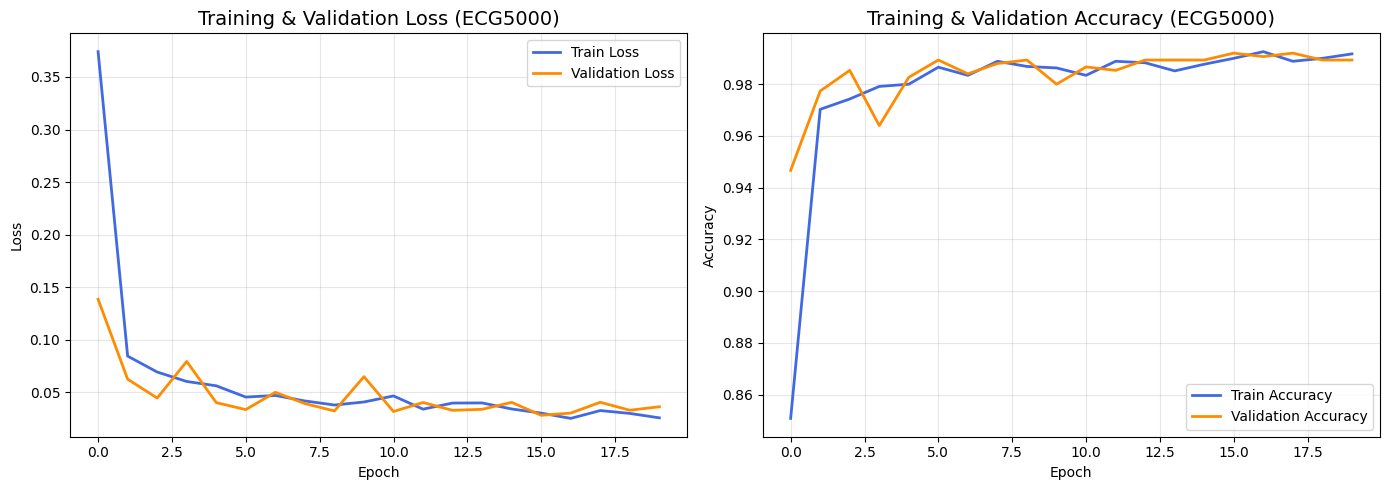

In [6]:
# 1. Train / Validation 학습 곡선 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['train_loss'], label='Train Loss', color='royalblue', lw=2)
axes[0].plot(history['val_loss'], label='Validation Loss', color='darkorange', lw=2)
axes[0].set_title('Training & Validation Loss (ECG5000)', fontsize=14)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history['train_acc'], label='Train Accuracy', color='royalblue', lw=2)
axes[1].plot(history['val_acc'], label='Validation Accuracy', color='darkorange', lw=2)
axes[1].set_title('Training & Validation Accuracy (ECG5000)', fontsize=14)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== 📊 ECG5000 Test Dataset Classification Report ===
              precision    recall  f1-score   support

  Normal (0)     0.9774    0.9886    0.9830       438
 Anomaly (1)     0.9837    0.9679    0.9758       312

    accuracy                         0.9800       750
   macro avg     0.9806    0.9783    0.9794       750
weighted avg     0.9800    0.9800    0.9800       750



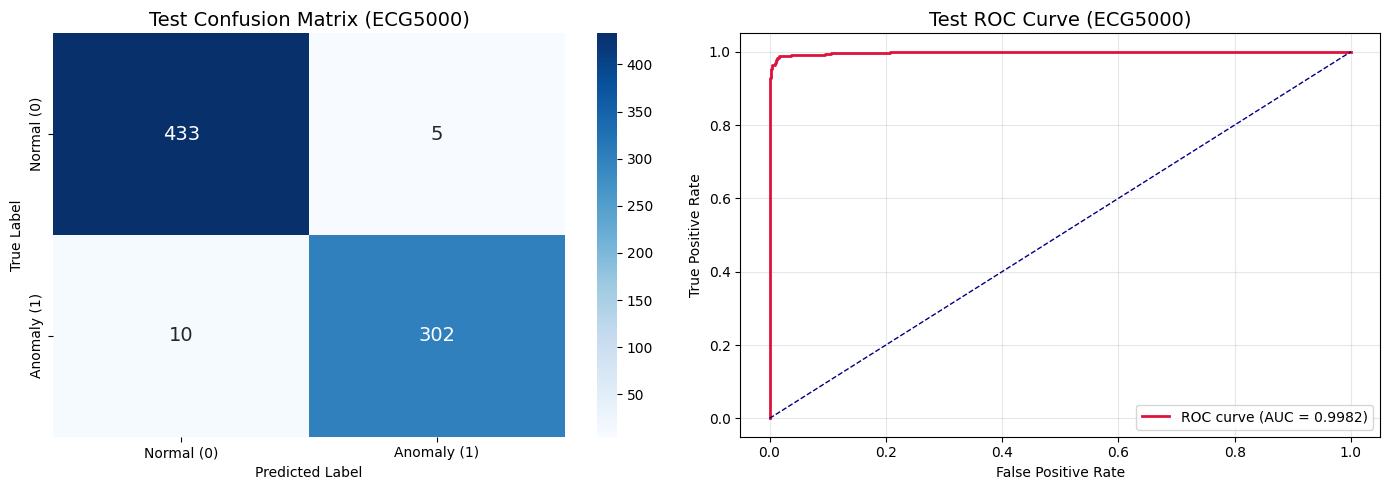

In [7]:
# 2. Test 데이터셋 평가 및 Confusion Matrix / ROC Curve 시각화
model.eval()
all_preds = []
all_probs = []
all_targets = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x = batch_x.to(device)
        outputs = model(batch_x)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
        all_targets.extend(batch_y.numpy())

all_preds = np.array(all_preds)
all_probs = np.array(all_probs)
all_targets = np.array(all_targets)

print('=== 📊 ECG5000 Test Dataset Classification Report ===')
print(classification_report(all_targets, all_preds, target_names=['Normal (0)', 'Anomaly (1)'], digits=4))

cm = confusion_matrix(all_targets, all_preds)
fpr, tpr, _ = roc_curve(all_targets, all_probs)
roc_auc = auc(fpr, tpr)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal (0)', 'Anomaly (1)'],
            yticklabels=['Normal (0)', 'Anomaly (1)'], annot_kws={'size': 14})
axes[0].set_title('Test Confusion Matrix (ECG5000)', fontsize=14)
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curve
axes[1].plot(fpr, tpr, color='crimson', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--')
axes[1].set_title('Test ROC Curve (ECG5000)', fontsize=14)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

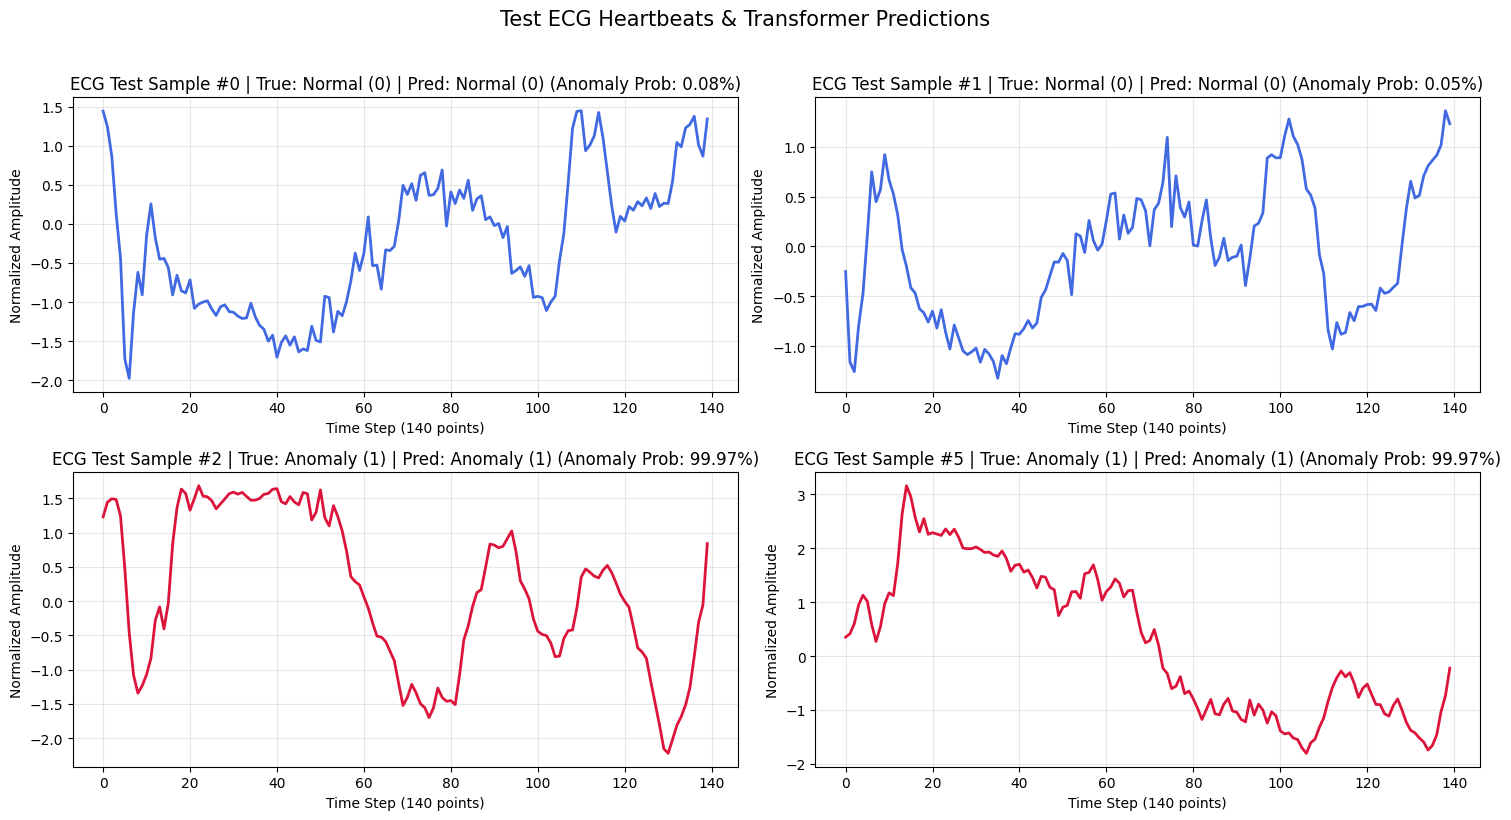

In [8]:
# 3. Test 샘플 심전도(ECG) 파형에 대한 예측 결과 및 이상 확률 시각화
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes = axes.flatten()

# 정상 심박 샘플 2개, 이상 심박 샘플 2개 선택
test_normal_indices = np.where(all_targets == 0)[0][:2]
test_anomaly_indices = np.where(all_targets == 1)[0][:2]
sample_indices = np.concatenate([test_normal_indices, test_anomaly_indices])

for i, idx in enumerate(sample_indices):
    series = X_test[idx].squeeze()
    true_label = 'Anomaly (1)' if all_targets[idx] == 1 else 'Normal (0)'
    pred_label = 'Anomaly (1)' if all_preds[idx] == 1 else 'Normal (0)'
    prob = all_probs[idx]

    color = 'crimson' if all_preds[idx] == 1 else 'royalblue'
    axes[i].plot(series, color=color, lw=2)
    axes[i].set_title(f'ECG Test Sample #{idx} | True: {true_label} | Pred: {pred_label} (Anomaly Prob: {prob:.2%})', fontsize=12)
    axes[i].set_xlabel('Time Step (140 points)')
    axes[i].set_ylabel('Normalized Amplitude')
    axes[i].grid(True, alpha=0.3)

plt.suptitle('Test ECG Heartbeats & Transformer Predictions', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()